# Active learning on the Uncertainty Engine (SDK)

Notebook 03 ran the GP and the acquisition *in this process*. This one builds the same
active-learning loop as **workflows on the remote Uncertainty Engine**, saves them to the
project workspace, and runs them there.

The structure follows the gold-miner example, which is the same shape of problem: samples
are expensive, so choose each next one to learn the most.

### Two environments

The engine library and the SDK are **both** published as `uncertainty-engine` and both
provide a top-level `uncertainty_engine` package — one is in-process modelling, the other
a remote API client. They cannot coexist in one virtualenv.

```bash
uv venv .venv-sdk --python 3.12
uv pip install --python .venv-sdk -e ../uncertainty-engine-sdk
uv pip install --python .venv-sdk --no-deps -e .
uv pip install --python .venv-sdk pandas numpy pyyaml pydantic matplotlib python-dotenv
```

**Run this notebook on the `.venv-sdk` kernel.** `dbtt.backend` reports which one you are on.

In [1]:
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dbtt import backend
from dbtt import sdk_workflows as W

print(backend.describe())

{'backend': 'sdk', 'version': '0.14.1', 'in_process_modelling': False, 'remote_workflows': True}


In [2]:
if not backend.has_sdk():
    raise SystemExit(
        "This notebook needs the SDK environment. Start it on the .venv-sdk kernel — "
        "see the setup block above."
    )

## 1. Credentials

Put `UE_USERNAME` and `UE_PASSWORD` in a `.env` file (copy `.env.example`), or in Colab's
Secrets panel. `load_credentials` reads Colab secrets first, then `.env`, and reports only
*where* the credentials came from — never what they are.

`.env` is gitignored. Do not commit real credentials.

In [3]:
source = W.load_credentials("../.env")
print(f"credential source: {source}")
print(f"credentials present: {W.credentials_present()}")

LIVE = W.credentials_present()
if not LIVE:
    print("\nNo credentials found — the notebook will build and inspect the workflows "
          "offline, and skip the cells that talk to the Engine.")

credential source: missing
credentials present: False

No credentials found — the notebook will build and inspect the workflows offline, and skip the cells that talk to the Engine.


## 2. The campaign so far

The same simulated data as the in-process notebooks. The Engine wants inputs and outputs
as separate datasets.

In [4]:
BOUNDS = (-150.0, 100.0)
PROJECT_NAME = "DBTT"          # must already exist — projects are created in the GUI
MODEL_NAME = "dbtt_gp"

temperatures = np.array([-150.0, -80.0, -40.0, 0.0, 100.0])
energies = np.array([5.6, 18.8, 104.2, 184.5, 196.9])

x_frame, y_frame = W.campaign_to_frames(temperatures, energies)
grid_frame = W.temperature_grid(BOUNDS, n=100)

display(x_frame.join(y_frame))
print(f"grid for visualisation: {len(grid_frame)} points from "
      f"{grid_frame['temperature_C'].min():.0f} to {grid_frame['temperature_C'].max():.0f} C")

,temperature_C,energy_J
0,-150.0,5.6
1,-80.0,18.8
2,-40.0,104.2
3,0.0,184.5
4,100.0,196.9


grid for visualisation: 100 points from -150 to 100 C


## 3. Connect and upload

Projects are created in the Uncertainty Engine GUI, not from the SDK, so `PROJECT_NAME`
must already exist.

In [5]:
client = project_id = None
resource_ids = {}

if LIVE:
    client, project_id = W.connect(PROJECT_NAME)
    print(f"connected as {client.email} | project {project_id}")

    resource_ids["x"] = W.upload_dataset(client, project_id, x_frame, "dbtt_temperatures")
    resource_ids["y"] = W.upload_dataset(client, project_id, y_frame, "dbtt_energies")
    resource_ids["grid"] = W.upload_dataset(client, project_id, grid_frame, "dbtt_grid")
    print(resource_ids)
else:
    # Placeholder ids, so the graphs below still build and can be inspected.
    resource_ids = {"x": "x-resource-id", "y": "y-resource-id", "grid": "grid-resource-id"}
    print("offline: using placeholder resource ids")

offline: using placeholder resource ids


## 4. Build the workflows

A workflow is a **graph** of nodes wrapped in a `Workflow` object. Nodes are wired by
*handles*: one node's named output becomes another's input. All three build without a
client, so you can inspect the structure before spending anything.

### 4a. Training — configure a GP, train it, save the model

In [6]:
train_workflow = W.build_training_workflow(
    client, project_id or "offline", resource_ids["x"], resource_ids["y"], MODEL_NAME
)

def show(workflow, title):
    print(f"--- {title}")
    for label, node in workflow.graph["nodes"].items():
        wired = {k: v["node_name"] for k, v in node["inputs"].items()
                 if isinstance(v, dict) and v.get("node_name") not in (None, "_")}
        print(f"  {label:20s} {node['type']:14s} <- {wired or '(external inputs)'}")

show(train_workflow, "TRAIN")

--- TRAIN
  GP config            ModelConfig    <- (external inputs)
  Load temperatures    LoadDataset    <- (external inputs)
  Load energies        LoadDataset    <- (external inputs)
  Train GP             TrainModel     <- {'config': 'GP config', 'inputs': 'Load temperatures', 'outputs': 'Load energies'}
  Save GP              Save           <- {'data': 'Train GP'}


Read the wiring: `Train GP` takes its `config` from the `GP config` node, its `inputs`
from the loaded temperatures and its `outputs` from the loaded energies; `Save GP` takes
the trained model. That is the whole training pipeline, declared rather than executed.

### 4b. Prediction — the model visualisation

In [7]:
predict_workflow = W.build_prediction_workflow(
    client, project_id or "offline", MODEL_NAME, resource_ids["grid"]
)
show(predict_workflow, "PREDICT (model visualisation)")

--- PREDICT (model visualisation)
  Load GP              LoadModel      <- (external inputs)
  Load grid            LoadDataset    <- (external inputs)
  Predict curve        PredictModel   <- {'model': 'Load GP', 'dataset': 'Load grid'}


### 4c. Recommendation — active learning

`Recommend` is the Engine's active-learning node. Our short acquisition names map onto its
`AvailableAcquisitions` values.

In [8]:
print(W.ACQUISITIONS)

recommend_workflow = W.build_recommendation_workflow(
    client, project_id or "offline", MODEL_NAME, acquisition="qNIPV", num_points=1
)
show(recommend_workflow, "RECOMMEND")

{'qNIPV': 'MonteCarloNegativeIntegratedPosteriorVariance', 'PSD': 'PosteriorStandardDeviation', 'EI': 'ExpectedImprovement', 'LogEI': 'LogExpectedImprovement'}
--- RECOMMEND
  Load GP              LoadModel      <- (external inputs)
  Recommend (qNIPV)    Recommend      <- {'model': 'Load GP'}


## 5. Save the workflows to the workspace

Saving puts each workflow in the project, where it appears in the GUI and can be re-run,
versioned and edited. This is the payoff of building them programmatically rather than
only executing them once.

In [9]:
if LIVE:
    saved = {}
    for name, workflow in [
        ("DBTT - train GP", train_workflow),
        ("DBTT - predict curve", predict_workflow),
        ("DBTT - recommend next test", recommend_workflow),
    ]:
        saved[name] = W.save_workflow(client, project_id, workflow, name)
        print(f"saved {name!r} -> {saved[name]}")
else:
    print("offline: skipping save (needs an authenticated client)")

offline: skipping save (needs an authenticated client)


## 6. Run the loop

Train, visualise, recommend — then break a specimen at the recommended temperature and go
round again. The simulator stands in for the test house.

In [10]:
if LIVE:
    W.run(client, train_workflow)
    print("trained")

    prediction = W.run(client, predict_workflow)
    recommendation = W.run(client, recommend_workflow)
    print("recommendation response:", recommendation.status.value)
else:
    print("offline: skipping execution")

offline: skipping execution


## 7. Feeding a recommendation back

In a real campaign the recommended temperature goes to the test house. Here the simulator
plays that role — note it lives in the *other* environment's dependency set only for the
heavy modelling; the simulator itself is pure numpy, so it runs here too.

tested at -25.0 C -> 149.79 J


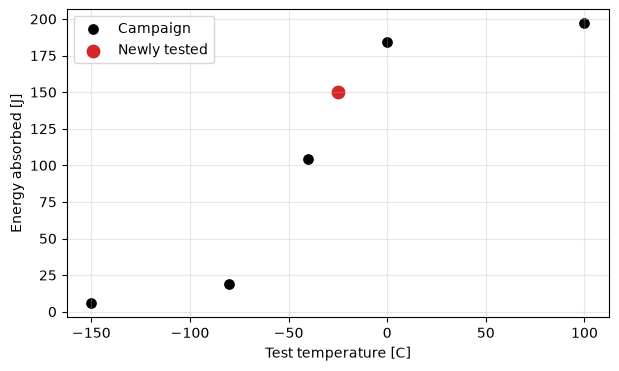

In [11]:
from dbtt import CharpySimulator, CharpySimulatorConfig

simulator = CharpySimulator(CharpySimulatorConfig.from_yaml("../configs/eurofer_eaf.yaml"))

next_temperature = -25.0   # replace with the Engine's recommendation when LIVE
result = simulator.simulate(next_temperature)
print(f"tested at {next_temperature} C -> {result.y[0]:.2f} J")

temperatures = np.append(temperatures, next_temperature)
energies = np.append(energies, result.y[0])

plt.figure(figsize=(7, 4))
plt.scatter(temperatures[:-1], energies[:-1], s=45, color="k", label="Campaign")
plt.scatter(temperatures[-1:], energies[-1:], s=80, color="tab:red", label="Newly tested")
plt.xlabel("Test temperature [C]"); plt.ylabel("Energy absorbed [J]")
plt.grid(alpha=0.3); plt.legend(); plt.show()

## What this notebook does and does not prove

**Verified:** all three workflow graphs build against the real SDK and are wired
correctly — `Train GP` pulls from the config and both datasets, `Save` from the trained
model, `Predict` and `Recommend` from the saved model. There are tests for exactly that
(`tests/test_sdk_workflows.py`, which skip unless run on the SDK environment).

**Not verified:** nothing here has been executed against a live Uncertainty Engine. That
needs your credentials and a project created in the GUI, so the upload, save and run steps
are guarded by `LIVE` and were skipped when this notebook was executed. Expect to fix
small things — resource naming collisions, node versions — on the first live run.